# EVAL BCS-CE65417 genmol

In [5]:
!pip install openpyxl rdkit msal

In [1]:
# import common libs
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
# import seaborn as sns


In [2]:
# Import the required classes
from capbet.evaluators.molgenevalsimple import MoleculeSetEvaluatorSimple
from capbet.core.wrappers.molecule import Molecule, MoleculeSet


# Load Data

In [6]:
# GT von Bayer
df = pd.read_excel("/home/ec2-user/SageMaker/data/raw/df_ICA_bionemo_eval_20250219.xlsx")
df.head()

,SUBSTANCE,SUBSTANCE_KEYS,std_smiles,AI_H,HSEC,AVEFA_PO_PROF,Lolium_PO_PROF,TRZAX_PO_PROF,AMAPA_PO_SEC_PROF,LOGD_neutral,LOGD_acid,SOL_mgL,SIP
0,BCS-DS23822,['BCS-DS23822'],C=C[C@]1(C(=O)N[C@H]2CO[C@@H](C(=O)O)C2)CC(c2c...,318.0,317.0,NaN,NaN,NaN,NaN,0.89,1.93,3050.00,NaN
1,BCS-DH85862,['BCS-DH85862'],Cc1cc(F)cc(C2=NO[C@@](C)(C(=O)N[C@H]3C=C[C@@H]...,338.0,231.0,NaN,NaN,NaN,NaN,2.72,2.80,28.30,NaN
2,BCS-CS64954,['BCS-CS64954'],COc1ccc(C2=NOC(C)(C(=O)NC3CC3)C2)cc1,0.0,0.0,NaN,NaN,NaN,NaN,1.79,1.77,68.65,NaN
3,BCS-CO63781,['BCS-CO63781'],CC1(C(=O)CCCC(=O)O)CC(c2cc(Cl)cc(Cl)c2)=NO1,120.0,92.0,NaN,NaN,NaN,NaN,1.11,2.72,1710.00,NaN
4,BCS-DC54916,['BCS-DC54916'],C=C[C@]1(C(=O)NCc2ccnc(OC)c2)CC(c2cc(F)cc(F)c2...,397.0,302.0,NaN,NaN,NaN,NaN,2.85,2.81,10.15,NaN


In [8]:
df_11 = pd.read_csv('../../data/interim/genmol/BCS-CE65417_R1_testmulti.csv')
df_12 = pd.read_csv('../../data/interim/genmol/BCS-CN20332_R1_testmulti.csv')
df_1 = pd.concat([df_11, df_12],ignore_index=True)
df_1.head()

,smiles,score
0,O=C(NCc1cccc(F)c1)C1CC([N+]Cl)=NO1,0.900
1,COC1=NOC(C(=O)NCc2cccc(I)c2)C1,0.835
2,O=C(Nc1[o+]cccc1O)C1CC(C(F)F)=NO1,0.808
3,COC(=O)c1ccc(C2=NOC(C(N)=O)C2)cc1,0.786
4,COCCC(=O)NC(=O)C1CC(C(C)C)=NO1,0.760


In [9]:
df_1.shape

(573, 2)

In [11]:
df_2 = pd.read_csv("../../data/processed/genmol/BCS-CE65417_moo-w-qsar.csv")
df_2.head()

,smiles,score
0,O=C(NCc1cccc(F)c1)C1CC([N+]Cl)=NO1,0.900
1,COC1=NOC(C(=O)NCc2cccc(I)c2)C1,0.835
2,O=C(Nc1[o+]cccc1O)C1CC(C(F)F)=NO1,0.808
3,COC(=O)c1ccc(C2=NOC(C(N)=O)C2)cc1,0.786
4,COCCC(=O)NC(=O)C1CC(C(C)C)=NO1,0.760


In [17]:
from by_scorer_new import MoleculeScorer

scorer = MoleculeScorer.create_scorer(
    use_qsar_hsec=False,
    use_qsar_aih=True,
    use_qed = False,
    use_similarity=True,
    similarity_weight=1.0,
    similarity_threshold=1.0,
)
#score the second dataset
df_2['AIH'] = scorer.get_qsar_aih_predictions(df_2['smiles'])
df_2.sort_values("AIH", ascending = False, inplace=True)
df_2.head()

,smiles,score,AIH
66,CCn1cc(CNC(=O)Cc2ccc(Br)cc2S)c(C)n1,0.797,94.24
223,COC(=O)CCNN(C(=O)C1CCCN1)c1cc(Cl)cc(Cl)c1,0.601,87.75
146,COC(=O)CCNC(=O)C1(c2cc(Cl)cc(Cl)c2)[C]C=C[CH]1,0.840,85.07
120,CCn1cc(CNCC(C)(C)C(O)=NCCC(C)C)c(C)n1,0.543,72.85
62,CCn1cc(CNC(=O)C2(C)CC2)c(C)n1,0.840,72.36


In [ ]:

#score the first dataset
df_1['AIH'] = scorer.get_qsar_aih_predictions(df_1['smiles'])
df_1.sort_values("AIH", ascending = False, inplace=True)
df1.head()

In [22]:

# Create sample datasets
print("\nCreating sample datasets...")

# Generated molecules (some valid, some invalid, some duplicates)
generated_smiles = df_1.smiles 

# Generated molecules (some valid, some invalid, some duplicates)
generated_smiles2 = df_2.smiles 

# Reference dataset (for novelty comparison)
reference_smiles = df.std_smiles

# Input dataset (for non-identicality comparison)
input_smiles = [
    "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
]

input_smiles2 = [
    "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
]
## first Bayer Seed
#m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
#m1_name = "BCS-CN20332" 

## second seed
#m2 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
#m2_name = "BCS-CE65417"



Creating sample datasets...


In [23]:

# Create MoleculeSet objects
print("Creating MoleculeSet objects...")
print("°°° DF1")
generated_set = MoleculeSet()
generated_set.add_from_smiles_list(generated_smiles)
print("°°° DF2")
generated_set2 = MoleculeSet()
generated_set2.add_from_smiles_list(generated_smiles2)
print("°°° DF-ref = Bayer")
reference_set = MoleculeSet()
reference_set.add_from_smiles_list(reference_smiles)

input_set = MoleculeSet()
input_set.add_from_smiles_list(input_smiles, ["BCS-CN20332"])

input_set2 = MoleculeSet()
input_set2.add_from_smiles_list(input_smiles2, ["BCS-CE65417"])


Creating MoleculeSet objects...
°°° DF1
°°° DF2
°°° DF-ref = Bayer


In [25]:

# Evaluate using fingerprint comparison
print("\nEvaluating using fingerprint comparison...")

fp_evaluator = MoleculeSetEvaluatorSimple(
    generated_set=generated_set,
    reference_set=reference_set,
    input_set=input_set,
    comparison_method='fingerprint',
    fingerprint_type='morgan',
    similarity_threshold=1
)

#fp_evaluator.print_report()
#fp_evaluator.plot_metrics(title="Molecule Metrics (Fingerprint Comparison)", save_path="fingerprint_unguided_LogP.png")
fp_evaluator.add_run("Guided MOO - BCS-CE65417")



Evaluating using fingerprint comparison...


In [26]:
# Now update the evaluator with the second dataset (ref stays the same)
fp_evaluator.generated_set = generated_set2  # Replace with second dataset
fp_evaluator.input_set = input_set2
# Evaluate and add the first run
#fp_evaluator.print_report()
#fp_evaluator.plot_metrics(title="Molecule Metrics (Unguided LogP)", save_path="fingerprint_unguided_LogP.png")
fp_evaluator.add_run("Unguided - BCS-CE65417")



Comparing all runs...


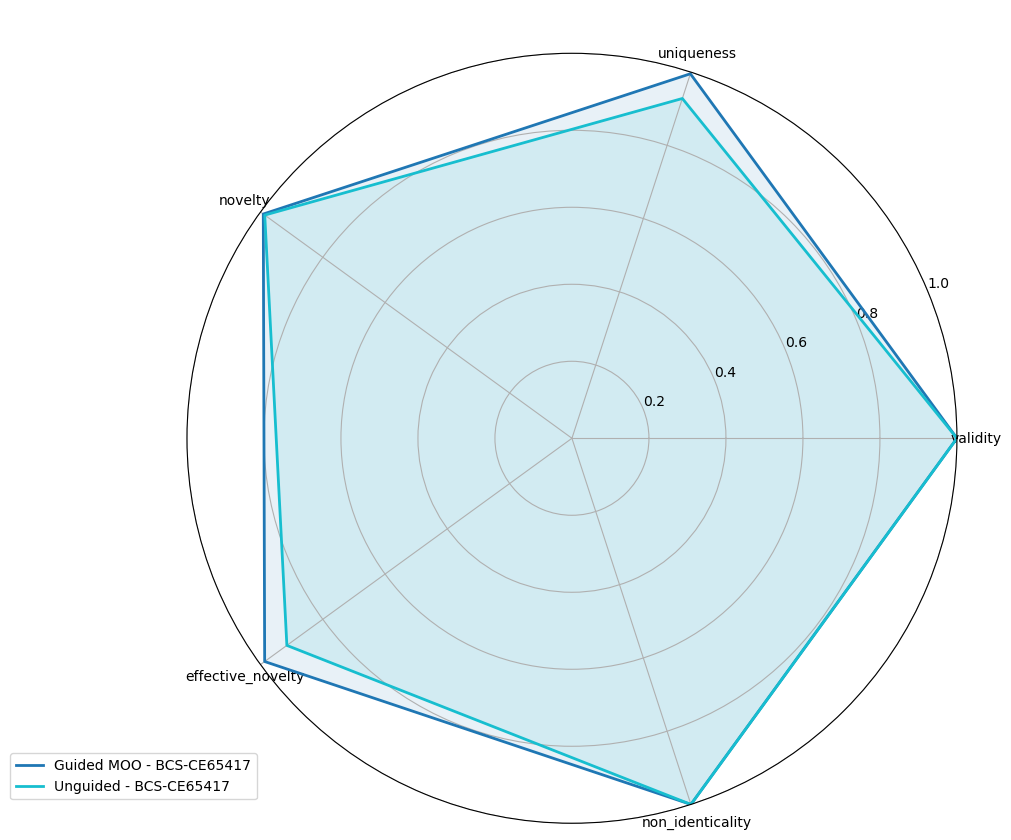

In [28]:

# Now compare all runs
print("\nComparing all runs...")
fp_evaluator.plot_multiple_runs(title=" ", save_path="Genmol_ug_vs_g.png")

In [29]:
fp_evaluator.print_report()

MOLECULE SET EVALUATION REPORT
Comparison Method: fingerprint
Fingerprint Type: morgan
Similarity Threshold: 1
------------------------------------------------------------
Validity: 1.0000 (100.00%)
Uniqueness: 0.9280 (92.80%)
Novelty: 0.9863 (98.63%)
Effective_novelty: 0.9153 (91.53%)
Non_identicality: 1.0000 (100.00%)
------------------------------------------------------------
Total molecules: 236
Valid molecules: 236
Unique molecules: 219
Novel molecules: 216
Non-identical molecules: 236

STATISTICS ACROSS RUNS
------------------------------------------------------------
Validity:
  mean: 1.0000
  median: 1.0000
  min: 1.0000
  max: 1.0000
  std: 0.0000

Uniqueness:
  mean: 0.9617
  median: 0.9617
  min: 0.9280
  max: 0.9955
  std: 0.0478

Novelty:
  mean: 0.9886
  median: 0.9886
  min: 0.9863
  max: 0.9910
  std: 0.0033

Effective_novelty:
  mean: 0.9509
  median: 0.9509
  min: 0.9153
  max: 0.9865
  std: 0.0504

Non_identicality:
  mean: 1.0000
  median: 1.0000
  min: 1.0000
  ma